In [7]:
import numpy as np
import pandas as pd
import scipy
import matplotlib.pyplot as plt
import seaborn as sns

print("Notebook is ready!")

Notebook is ready!


In [8]:
import scipy.io

train = scipy.io.loadmat('../../data/train.mat')
val = scipy.io.loadmat('../../data/val.mat')
test = scipy.io.loadmat('../../data/test.mat')
X_train = train['trainData']       # shape: (393, 5000)
y_train = [label[0] for label in train['trainLabels'].flatten()]
X_val = val['valData']  
X_test = test['testData']  

In [9]:
X_train.shape

(393, 5000)

In [10]:
X_train #so its a matrix

array([[-0.09863087,  0.6682042 , -0.8850567 , ..., -0.3289459 ,
        -1.295652  , -0.1114658 ],
       [-0.281101  ,  0.6282719 , -0.3082969 , ..., -0.05248418,
        -0.8620571 , -0.5784704 ],
       [-0.05087212,  0.1058913 , -1.450126  , ..., -0.08228879,
         0.2121764 , -0.2710719 ],
       ...,
       [-0.37898134,  0.9096594 , -0.43558826, ...,  0.93972743,
         1.18717775, -0.1175061 ],
       [ 0.97838231,  1.56430759,  0.34363318, ...,  0.91237275,
         0.36439539, -0.29428467],
       [-0.9013591 ,  0.41399404, -1.16215609, ...,  0.67392038,
         0.74190355,  0.09745445]], shape=(393, 5000))

In [11]:
type(X_train)

numpy.ndarray

In [12]:
np.isnan(X_train).sum() #no null values

np.int64(0)

In [13]:
classes, counts = np.unique(X_train, return_counts=True)
print(len(classes))
print(len(counts)) #all unique values

1323573
1323573


In [14]:
classes_y, counts_y = np.unique(y_train, return_counts=True)
print(classes_y, counts_y) #equal split

['InnerRaceFault' 'Normal' 'OuterRaceFault'] [131 131 131]


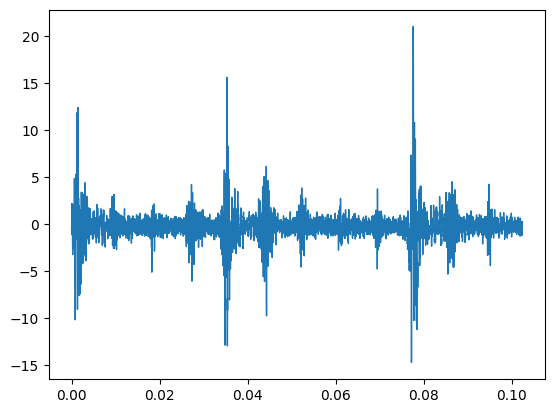

In [15]:
SAMPLE_RATE = 48_828
time = np.arange(X_train.shape[1]) / SAMPLE_RATE
plt.plot(
    time,
    X_train[34],
    linewidth=1
)


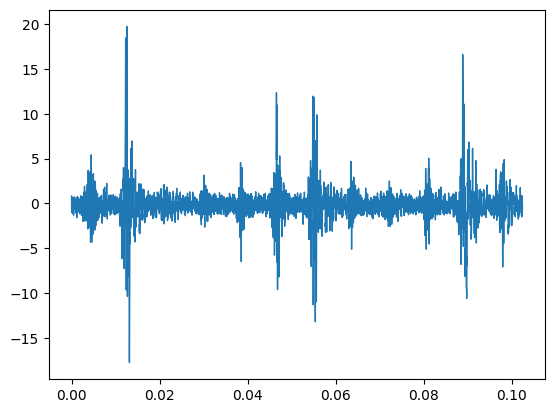

In [16]:

plt.plot(
    time,
    X_train[100],
    linewidth=1
)


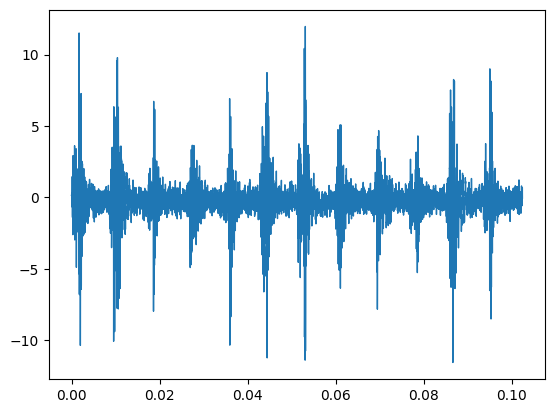

In [17]:

plt.plot(
    time,
    X_train[3],
    linewidth=1
)

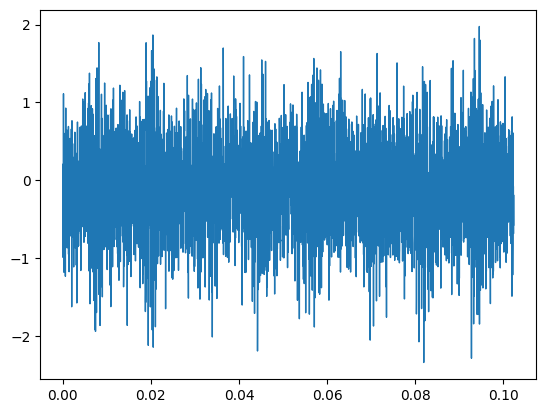

In [18]:
plt.plot(
    time,
    X_train[140],
    linewidth=1
)

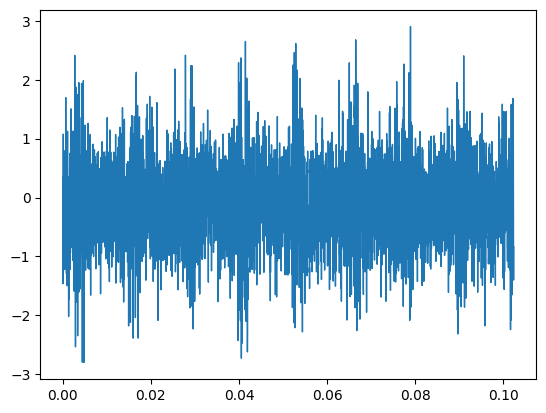

In [19]:
plt.plot(
    time,
    X_train[200],
    linewidth=1
)

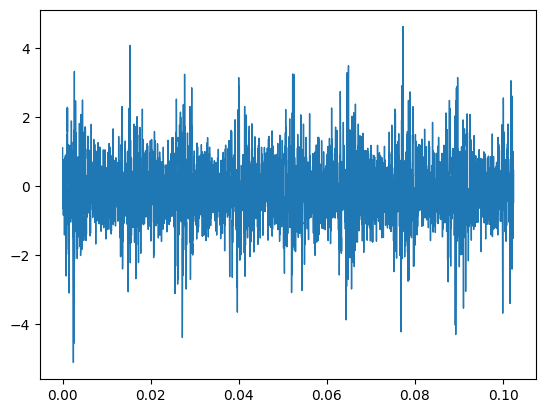

In [20]:
plt.plot(
    time,
    X_train[236],
    linewidth=1
)

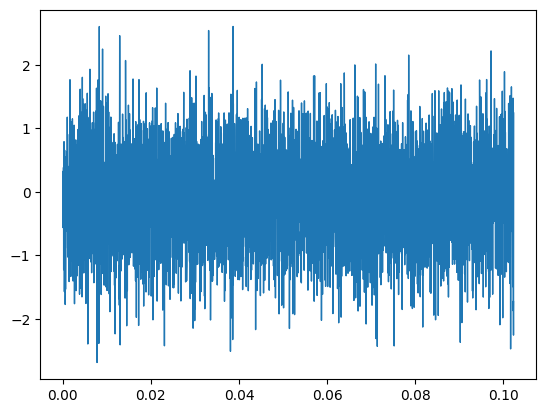

In [21]:
plt.plot(
    time,
    X_train[300],
    linewidth=1
)

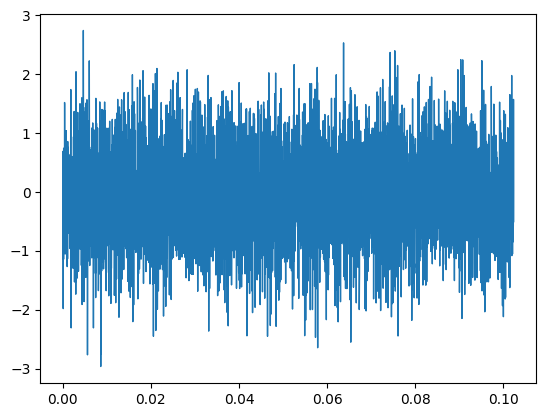

In [22]:
plt.plot(
    time,
    X_train[350],
    linewidth=1
)

In [23]:
signal_stats_df = pd.DataFrame({
    "label": y_train,
    "mean": np.mean(X_train, axis=1),
    "median": np.median(X_train, axis=1),
    "std": np.std(X_train, axis=1),
    "min": np.min(X_train, axis=1),
    "max": np.max(X_train, axis=1)
})

signal_stats_df.head()

,label,mean,median,std,min,max
0,InnerRaceFault,-0.211336,-0.216206,2.256738,-22.69226,23.38188
1,InnerRaceFault,-0.219043,-0.220452,1.695879,-15.99298,20.11251
2,InnerRaceFault,-0.203583,-0.208325,1.958869,-17.73318,22.91833
3,InnerRaceFault,-0.233934,-0.233551,1.511303,-11.56701,11.96552
4,InnerRaceFault,-0.242097,-0.232856,1.687088,-16.95024,18.61170


In [24]:
class_stats_df = (
    signal_stats_df
    .groupby("label", as_index=False)
    .mean(numeric_only=True)
)

class_stats_df

,label,mean,median,std,min,max
0,InnerRaceFault,-0.214793,-0.216555,1.873487,-20.017273,21.509217
1,Normal,-0.103363,-0.103929,0.769385,-2.966405,2.753936
2,OuterRaceFault,-0.143206,-0.145204,0.869852,-5.081703,4.972477


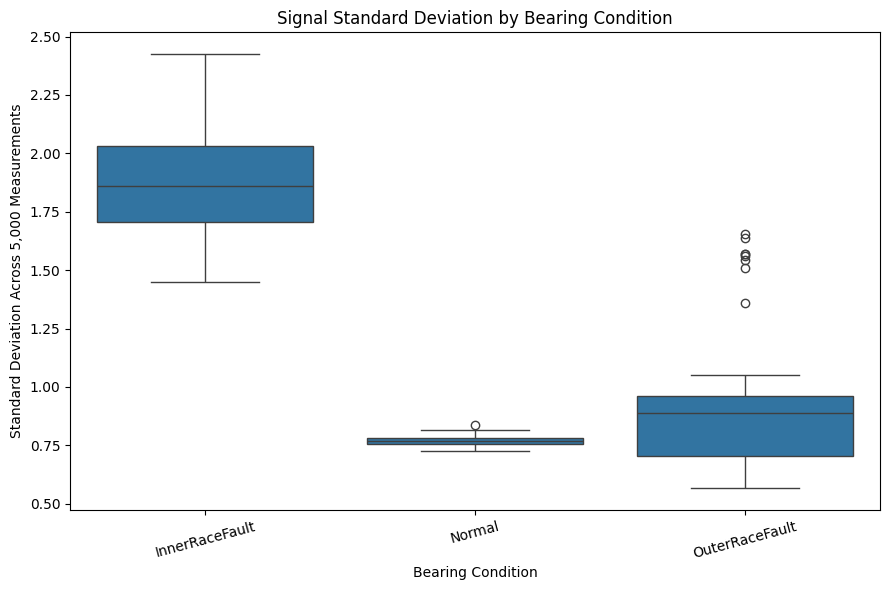

In [25]:

signal_std = np.std(X_train, axis=1)

# Connect each signal's standard deviation to its class label
std_df = pd.DataFrame({
    "label": y_train,
    "standard_deviation": signal_std
})

class_order = [
    "InnerRaceFault",
    "Normal",
    "OuterRaceFault"
]

# Each box is constructed from the 131 signal standard deviations
# belonging to that class
plt.figure(figsize=(9, 6))

sns.boxplot(
    data=std_df,
    x="label",
    y="standard_deviation",
    order=class_order
)

plt.title("Signal Standard Deviation by Bearing Condition")
plt.xlabel("Bearing Condition")
plt.ylabel("Standard Deviation Across 5,000 Measurements")
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

In [26]:
y_train[135]

np.str_('OuterRaceFault')

In [27]:
from scipy.stats import skew, kurtosis
signal_features = pd.DataFrame({
    "label": y_train,
    "rms": np.sqrt(np.mean(X_train**2, axis=1)), #overall intensity
    "peak_to_peak": np.ptp(X_train, axis=1),
    "max_absolute": np.max(np.abs(X_train), axis=1),
    "skewness": skew(X_train, axis=1),
    "kurtosis": kurtosis(X_train, axis=1), #how peaky, outlier prone, >3
    "sd": np.std(X_train, axis=1)
})
#rms bigger for irf, kurtosis very large for irf

In [28]:
signal_features

,label,rms,peak_to_peak,max_absolute,skewness,kurtosis,sd
0,InnerRaceFault,2.266612,46.074140,23.381880,0.881582,30.608330,2.256738
1,InnerRaceFault,1.709966,36.105490,20.112510,1.242787,32.116261,1.695879
2,InnerRaceFault,1.969420,40.651510,22.918330,1.342349,37.047306,1.958869
3,InnerRaceFault,1.529301,23.532530,11.965520,-0.052928,12.788447,1.511303
4,InnerRaceFault,1.704370,35.561940,18.611700,0.543406,22.348582,1.687088
...,...,...,...,...,...,...,...
388,Normal,0.811260,5.716608,3.052651,0.040190,-0.066558,0.797879
389,Normal,0.806712,6.408618,3.513643,0.001651,0.096905,0.793133
390,Normal,0.803414,5.932257,3.091363,-0.008725,-0.010698,0.802018
391,Normal,0.756374,5.609699,2.839220,0.009006,0.062765,0.754621


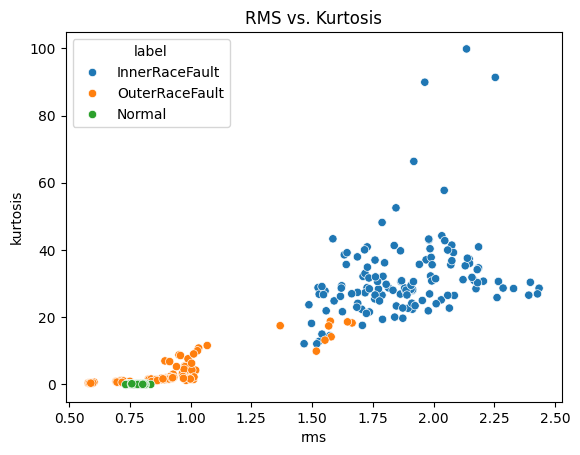

In [29]:
sns.scatterplot(
    data=signal_features,
    x="rms",
    y="kurtosis",
    hue="label"
)

plt.title("RMS vs. Kurtosis")
plt.show()
#>1.5 rms, 20 kurtosis = irf
#orf and normal overlaps

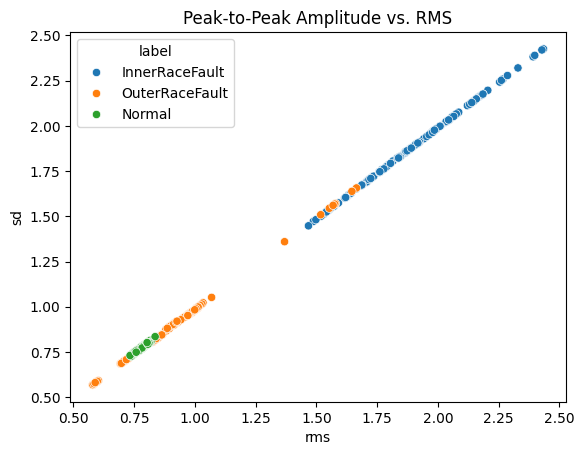

In [30]:
sns.scatterplot(
    data=signal_features,
    x="rms",
    y="sd",
    hue="label"
)

plt.title("Peak-to-Peak Amplitude vs. RMS")
plt.show()

In [31]:
#look more into frequency domain analysis: x: freq, y: strength of that freq

In [32]:
#global standardization
train_mean = np.mean(X_train)
train_std = np.std(X_train)

print("Training mean:", train_mean)
print("Training standard deviation:", train_std)

Training mean: -0.1537873379955809
Training standard deviation: 1.2870536466273186


In [33]:
X_train_scaled = (X_train - train_mean) / train_std
X_val_scaled = (X_val - train_mean) / train_std
X_test_scaled = (X_test - train_mean) / train_std

In [34]:
print("Scaled train mean:", np.mean(X_train_scaled))
print("Scaled train std:", np.std(X_train_scaled))

print("Scaled validation mean:", np.mean(X_val_scaled))
print("Scaled validation std:", np.std(X_val_scaled))

print("Scaled test mean:", np.mean(X_test_scaled))
print("Scaled test std:", np.std(X_test_scaled))

Scaled train mean: 1.4767717724398215e-16
Scaled train std: 0.9999999999999999
Scaled validation mean: -0.0038759722856685115
Scaled validation std: 0.9557864399278581
Scaled test mean: 0.0019208729687847992
Scaled test std: 1.003828657489283


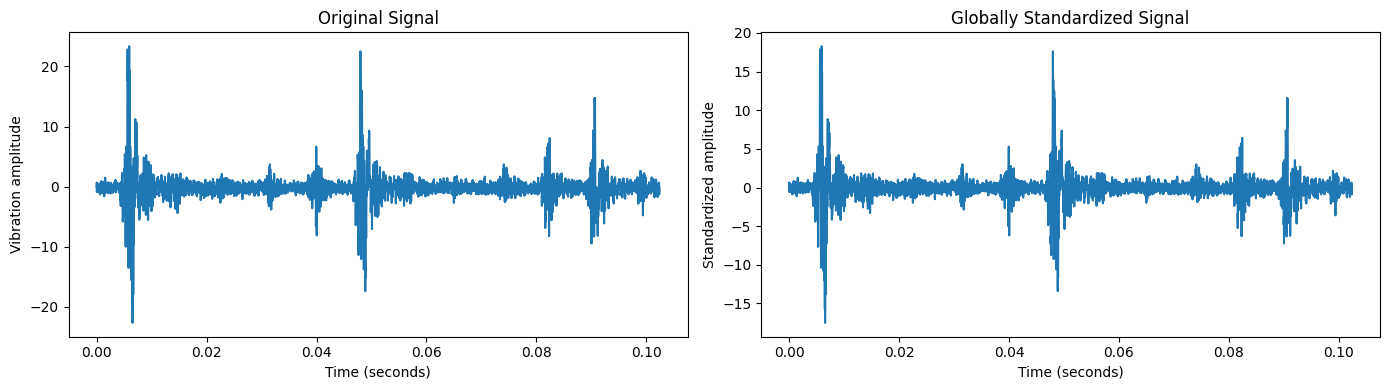

In [35]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))

axes[0].plot(time, X_train[0])
axes[0].set_title("Original Signal")
axes[0].set_xlabel("Time (seconds)")
axes[0].set_ylabel("Vibration amplitude")

axes[1].plot(time, X_train_scaled[0])
axes[1].set_title("Globally Standardized Signal")
axes[1].set_xlabel("Time (seconds)")
axes[1].set_ylabel("Standardized amplitude")

plt.tight_layout()
plt.show()

-0.1537873379955809


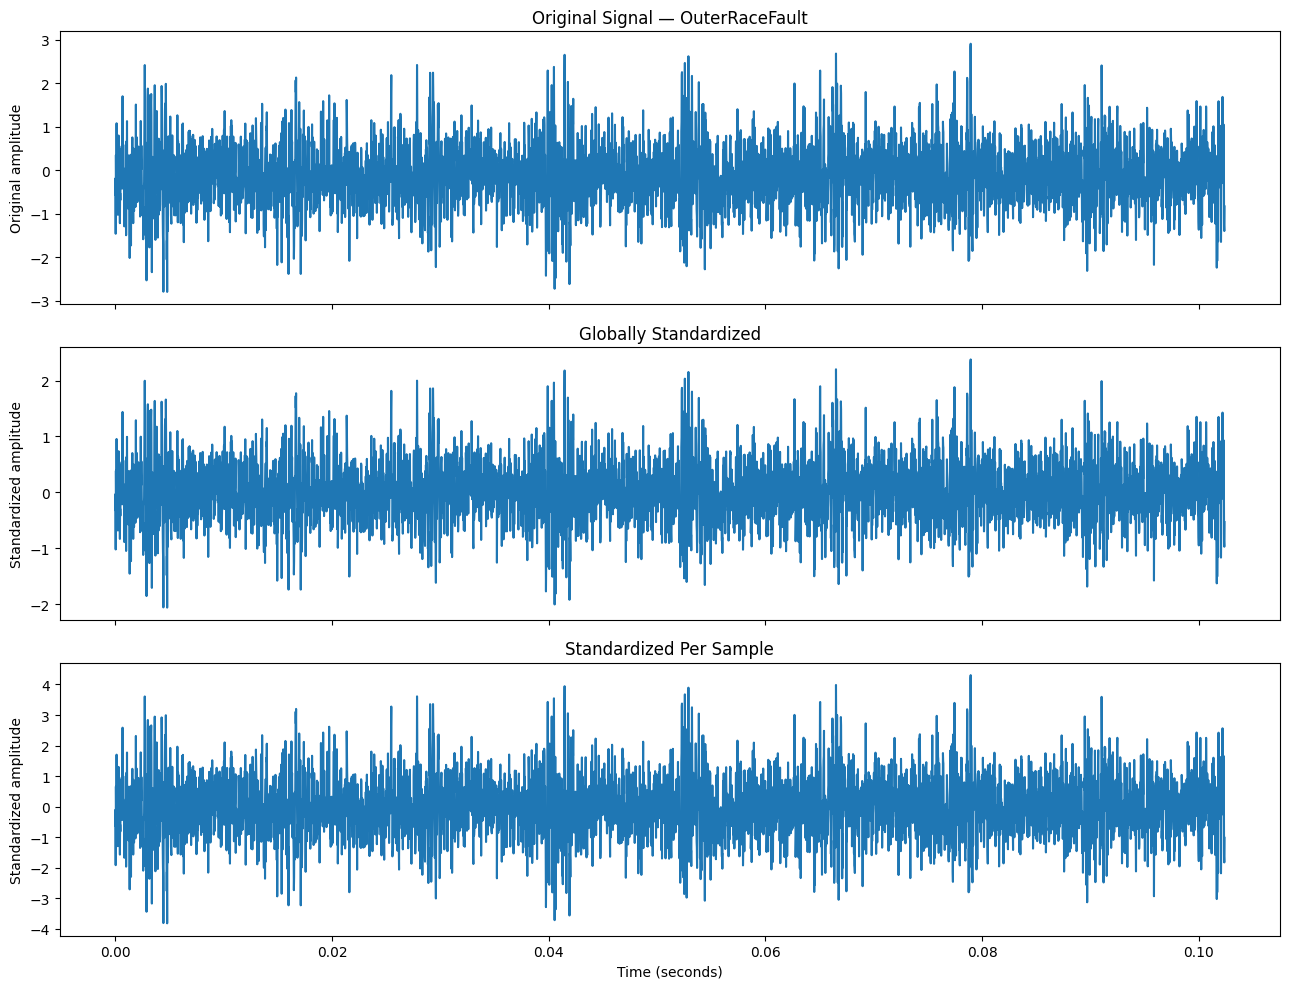

In [40]:
import numpy as np
import matplotlib.pyplot as plt

SAMPLE_RATE = 48_828
time = np.arange(X_train.shape[1]) / SAMPLE_RATE

# Choose one signal
sample_index = 200
original_signal = X_train[sample_index]

global_mean = np.mean(X_train)
global_std = np.std(X_train)

print(global_mean)

globally_standardized_signal = (
    original_signal - global_mean
) / global_std

sample_mean = np.mean(original_signal)
sample_std = np.std(original_signal)

per_sample_standardized_signal = (
    original_signal - sample_mean
) / sample_std

fig, axes = plt.subplots(3, 1, figsize=(13, 10), sharex=True)

axes[0].plot(time, original_signal)
axes[0].set_title(
    f"Original Signal — {y_train[sample_index]}"
)
axes[0].set_ylabel("Original amplitude")

axes[1].plot(time, globally_standardized_signal)
axes[1].set_title("Globally Standardized")
axes[1].set_ylabel("Standardized amplitude")

axes[2].plot(time, per_sample_standardized_signal)
axes[2].set_title("Standardized Per Sample")
axes[2].set_xlabel("Time (seconds)")
axes[2].set_ylabel("Standardized amplitude")

plt.tight_layout()
plt.show()